# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
**Q2.** What are its two main components?  
**Q3.** What is the role of `CLIPProcessor`?  
**Q4.** What is the role of `CLIPModel`?

In [1]:
# Run this cell first.
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [2]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cuda


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

### Answers

**Q1.** CLIP is a model from OpenAI that learned to match images with text. It was trained on a huge number of images with their captions, so it knows which descriptions go with which pictures.

**Q2.** An image encoder (a Vision Transformer) and a text encoder (a Transformer). Both turn their input into a vector of the same size, so the two can be compared.

**Q3.** It gets the inputs ready for the model. It resizes and normalizes the image and turns the text into tokens.

**Q4.** It's the model itself. It computes the image and text embeddings and the similarity scores between them.

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

Image size: (6000, 4000)
Image mode: RGB


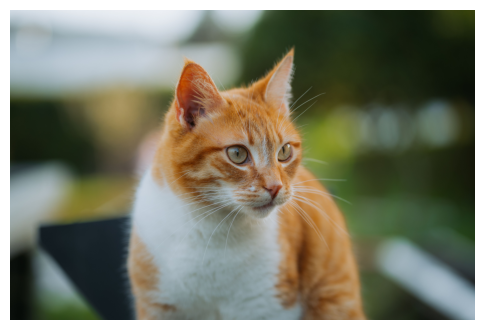

In [3]:
# Upload an image in Google Colab/Jupyter and change the filename if necessary.
IMAGE_PATH = "./cat.jpg"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

### Answers

**Q5.** 6000 x 4000 pixels.

**Q6.** Pixels in RGB mode, so each pixel has a red, green and blue value between 0 and 255.

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

In [4]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.9863
a photo of a dog                   : 0.0067
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0007
a photo of a person                : 0.0061


### Answers

**Q7.** "a photo of a cat", with a probability of about 0.99.

**Q8.** Yes, the picture is a cat.

**Q9.** Because CLIP puts images and text in the same vector space. During training it learned to put an image close to its caption, so comparing an image with a sentence is just measuring how close their vectors are.

**Q10.** It turns the raw scores into probabilities that add up to 1.

## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

In [5]:
# STUDENT TASK
def classify_image(image, classes):
    inputs = processor(
        text=classes,
        images=image,
        return_tensors="pt",
        padding=True
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model(**inputs)
    probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()
    max_prob = torch.argmax(probs).item()
    return classes[max_prob], probs[max_prob].item()
    
classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

# Uncomment after implementing the function:
prediction, probability = classify_image(image, classes)
print("Prediction:", prediction)
print("Probability:", probability)

Prediction: cat
Probability: 0.9898899793624878


### Answers

**Q11.** Classifying an image into categories the model was never specifically trained on. You just give it the class names as text and it picks the closest one.

**Q12.** CLIP already learned how images and words relate during pre-training. The class names are enough, so there's no need to collect labeled images and train something new.

**Q13.** It still picks one of the classes you gave it, even though none of them is right, and it can be quite confident about it.

## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [6]:
# STUDENT TASK
dataset = [
    ("test_images/cats/cat1.jpg", "cat"),
    ("test_images/cats/cat2.jpg", "cat"),
    ("test_images/cats/cat3.jpg", "cat"),
    ("test_images/cats/cat4.jpg", "cat"),
    ("test_images/cats/cat5.jpg", "cat"),
    ("test_images/dogs/dog1.jpg", "dog"),
    ("test_images/dogs/dog2.jpg", "dog"),
    ("test_images/dogs/dog3.jpg", "dog"),
    ("test_images/dogs/dog4.jpg", "dog"),
    ("test_images/dogs/dog5.jpg", "dog"),
]

# Load every image once: (filename, PIL image, actual class)
images = [(path, Image.open(path).convert("RGB"), label) for path, label in dataset]
print(f"Loaded {len(images)} images")

# Evaluation
classes = ["cat", "dog", "car", "airplane", "horse", "bird"]
rows = []
for path, img, actual in images:
    predicted, probability = classify_image(img, classes)
    rows.append({"image": path, "actual": actual, "predicted": predicted,
                 "probability": round(probability, 4), "correct": predicted == actual})

results = pd.DataFrame(rows)
display(results)
n_correct = int(results["correct"].sum())
print(f"Accuracy = {n_correct}/{len(results)} = {n_correct / len(results):.2%}")
print("Misclassified:", results.loc[~results["correct"], "image"].tolist() or "none")

Loaded 10 images


,image,actual,predicted,probability,correct
0,test_images/cats/cat1.jpg,cat,cat,0.9418,True
1,test_images/cats/cat2.jpg,cat,cat,0.9807,True
2,test_images/cats/cat3.jpg,cat,cat,0.9912,True
3,test_images/cats/cat4.jpg,cat,cat,0.9878,True
4,test_images/cats/cat5.jpg,cat,cat,0.9813,True
5,test_images/dogs/dog1.jpg,dog,dog,0.9309,True
6,test_images/dogs/dog2.jpg,dog,dog,0.9894,True
7,test_images/dogs/dog3.jpg,dog,dog,0.9876,True
8,test_images/dogs/dog4.jpg,dog,dog,0.9926,True
9,test_images/dogs/dog5.jpg,dog,dog,0.9884,True


Accuracy = 10/10 = 100.00%
Misclassified: none


### Answers

**Q14.** 10 out of 10, so 100%.

**Q15.** None. The lowest confidence was dog1.jpg at 0.93, which is also the smallest image (240x240).

**Q16.** There were no errors with these images, but CLIP could get things wrong when:
- the image is small, blurry or taken from a strange angle
- there's more than one object, so it's not clear what the main subject is
- the classes look alike, or the prompt is badly worded

## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**Q18.** Which prompt gives the highest score?  
**Q19.** What does this demonstrate about prompt formulation?

In [7]:
# STUDENT TASK
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

# Calculate and compare the scores for all prompts (on the cat image from Exercise 2).
cat_image = Image.open(IMAGE_PATH).convert("RGB")
inputs = processor(text=prompts, images=cat_image, return_tensors="pt", padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}
with torch.no_grad():
    outputs = model(**inputs)

scores = outputs.logits_per_image[0].cpu()   # 100 * cosine similarity
probs = scores.softmax(dim=0)
for prompt, score, p in sorted(zip(prompts, scores, probs), key=lambda x: -x[1]):
    print(f"{prompt:35s} score={score.item():6.2f}  softmax={p.item():.3f}")

a photo of a cat                    score= 29.23  softmax=0.432
a photograph showing a cat          score= 29.01  softmax=0.349
a domestic animal called a cat      score= 27.72  softmax=0.095
an image containing a cat           score= 27.67  softmax=0.091
a cat                               score= 26.63  softmax=0.032


### Answers

**Q17.** No, they're all a bit different even though every prompt means "cat".

**Q18.** "a photo of a cat" scored highest (29.2). Just "a cat" scored lowest (26.6).

**Q19.** The way you phrase the prompt changes the result. CLIP was trained on image captions, so prompts that sound like a caption tend to work better.

# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

24 images -> embeddings (24, 512)
1. football4.jpg      cosine=0.2764
2. football2.jpg      cosine=0.2667
3. football1.jpg      cosine=0.2621
4. football3.jpg      cosine=0.2458
5. dog4.jpg           cosine=0.2112


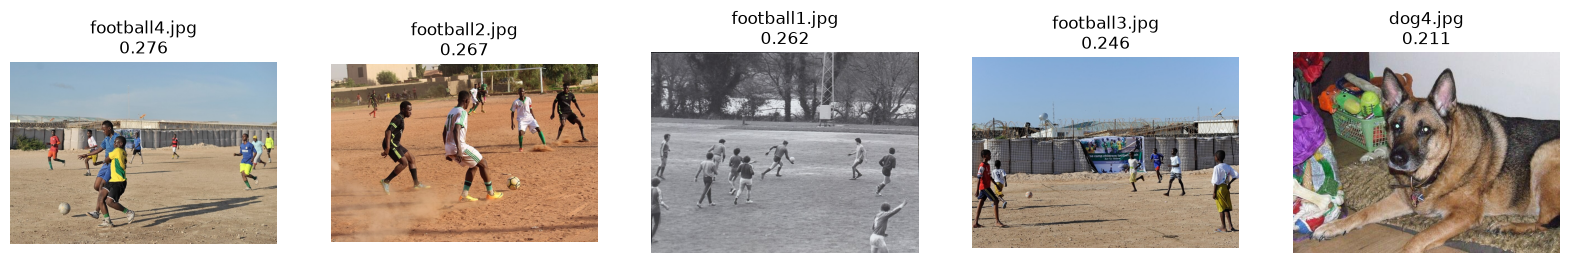

In [8]:
# STUDENT TASK
# 1. Put your images in IMAGE_DIR.
# 2. Compute image embeddings.
# 3. Compute the query embedding.
# 4. Calculate cosine similarity.
# 5. Display Top-5 images.
import glob
import os

IMAGE_DIR = "images"
QUERY = "a person playing football"


def as_tensor(features):
    # transformers 5 may wrap the projected features in an output object
    return features if torch.is_tensor(features) else features.pooler_output


# Exercise 7: normalized CLIP embedding for every image
paths = sorted(glob.glob(os.path.join(IMAGE_DIR, "*.jpg")))
db_images = [Image.open(p).convert("RGB") for p in paths]
with torch.no_grad():
    image_inputs = processor(images=db_images, return_tensors="pt").to(device)
    image_embeddings = as_tensor(model.get_image_features(**image_inputs))
image_embeddings = image_embeddings / image_embeddings.norm(dim=-1, keepdim=True)
print(f"{len(paths)} images -> embeddings {tuple(image_embeddings.shape)}")

# Exercise 8: query embedding, cosine similarity, Top-5
with torch.no_grad():
    text_inputs = processor(text=[QUERY], return_tensors="pt", padding=True).to(device)
    text_embedding = as_tensor(model.get_text_features(**text_inputs))
text_embedding = text_embedding / text_embedding.norm(dim=-1, keepdim=True)

similarity = (image_embeddings @ text_embedding.T).squeeze(1).cpu()
top = similarity.topk(5)
for rank, (score, i) in enumerate(zip(top.values, top.indices), 1):
    print(f"{rank}. {os.path.basename(paths[i]):18s} cosine={score.item():.4f}")

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, score, i in zip(axes, top.values, top.indices):
    ax.imshow(db_images[i])
    ax.set_title(f"{os.path.basename(paths[i])}\n{score.item():.3f}")
    ax.axis("off")
plt.show()

### Answers

I used 24 images in the `images` folder (football, cars, food, buildings, landscapes and animals).

**Q20.** football4.jpg, a photo of kids playing football.

**Q21.** Yes. The top 4 results are the 4 football pictures. The 5th one is a dog, but its score is clearly lower, and there were only 4 football images to find.

**Q22.** The query text is turned into a vector and compared directly with the image vectors. Nothing about the images has to be labeled beforehand.

**Q23.** Searching your photo gallery by typing something like "beach at sunset", or searching products in an online shop by description.

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
______________
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**Q25.** Why is a projection layer required?  
**Q26.** What is the role of the language model?

### Answers

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
Projection layer
  |
  v
Language Model
  |
  v
Text Response
```

**Q24.** It looks at the image and turns it into features (vectors) that describe what's in it.

**Q25.** The image features and the language model's word embeddings don't have the same format or size. The projection layer converts the image features so the language model can read them like words.

**Q26.** It reads the image features together with the question and writes the answer.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 32001. This may result in unexpected behavior.


W1019 21:53:16.349000 30920 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

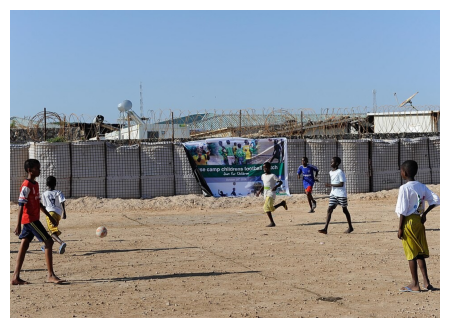

Q: What is happening in this image?


A: In the image, a group of people is playing soccer on a dirt field. They are actively engaged in the game, with some players running and others kicking the soccer ball. The scene takes place in a fenced-in area, which could be a makeshift soccer field.

Q: How many people are visible?


A: There are four people visible in the image.

Q: What objects can you identify?


A: In the image, you can identify a soccer ball, a group of people playing soccer, and a fence. The group of people is actively engaged in a soccer game, with some of them running towards the soccer ball. The fence is located near the playing area, possibly serving as a boundary or a barrier to keep the ball within the playing area.

Q: Describe the image in detail.


A: The image depicts a group of young people playing soccer on a dirt field. There are at least nine people in the scene, with some of them actively participating in the game while others are watching or waiting for their turn. 

A sports ball is visible in the middle of the field, and a bench can be seen nearby, possibly for players to rest or for spectators to sit. The scene captures the excitement and camaraderie of a casual soccer game among friends.



In [9]:
# LLaVA reference implementation.
# A published 4-bit LLaVA-1.5-7B checkpoint: about 4 GB of VRAM instead of 14 GB.
from transformers import AutoProcessor, LlavaForConditionalGeneration

MODEL_ID = "unsloth/llava-1.5-7b-hf-bnb-4bit"
processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="cuda:0"
)


def ask_llava(image, question, max_new_tokens=120):
    prompt = f"USER: <image>\n{question} ASSISTANT:"
    inputs = processor_llava(images=image, text=prompt, return_tensors="pt").to(llava.device, torch.float16)
    with torch.no_grad():
        output = llava.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return processor_llava.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()


llava_image = Image.open("images/football3.jpg").convert("RGB")
plt.figure(figsize=(6, 4)); plt.imshow(llava_image); plt.axis("off"); plt.show()

for question in [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail.",
]:
    print("Q:", question)
    print("A:", ask_llava(llava_image, question, max_new_tokens=200 if "detail" in question else 80))
    print()

### Answers

I used `unsloth/llava-1.5-7b-hf-bnb-4bit`, a 4-bit version of LLaVA 1.5 7B that fits in about 4 GB of GPU memory. The image is `images/football3.jpg`, kids playing football on a dirt field.

1. **What is happening?** It said a group of people playing soccer on a dirt field. Correct.
2. **How many people?** It said four. Wrong, there are 6.
3. **What objects?** A ball, people and a fence. Correct, but it missed the big banner.
4. **Detailed description:** Mostly right, but now it says "at least nine people" and mentions a bench that isn't there.

## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

In [10]:
# Exercise 11: 5 images x 5 questions
vqa_images = ["images/football2.jpg", "images/pizza1.jpg", "images/horse1.jpg",
              "images/landscape1.jpg", "images/building1.jpg"]
vqa_questions = [
    "How many people are visible?",
    "What objects can you see?",
    "Where is this scene?",
    "What is happening in the image?",
    "What are the main colors in the image?",
]

rows = []
for path in vqa_images:
    img = Image.open(path).convert("RGB")
    for question in vqa_questions:
        rows.append({"Image": os.path.basename(path), "Question": question,
                     "LLaVA Answer": ask_llava(img, question + " Answer briefly.", max_new_tokens=60)})

vqa = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", None)
display(vqa)

,Image,Question,LLaVA Answer
0,football2.jpg,How many people are visible?,10
1,football2.jpg,What objects can you see?,Soccer ball
2,football2.jpg,Where is this scene?,Africa
3,football2.jpg,What is happening in the image?,Soccer players are playing soccer on a dirt field.
4,football2.jpg,What are the main colors in the image?,Green and yellow
5,pizza1.jpg,How many people are visible?,0
6,pizza1.jpg,What objects can you see?,Plate
7,pizza1.jpg,Where is this scene?,Kitchen
8,pizza1.jpg,What is happening in the image?,A plate of food is being served.
9,pizza1.jpg,What are the main colors in the image?,Red and green


In [11]:
# Human evaluation: checked by looking at each image (True = answer correct)
vqa["Human Evaluation"] = [False, True, False, True, False, True, True, False, True, True, True, True, True, True, True, True, True, False, True, True, True, True, True, True, True]
display(vqa)
print(f"VQA accuracy = {vqa['Human Evaluation'].sum()}/{len(vqa)} = {vqa['Human Evaluation'].mean():.0%}")
display(vqa.groupby("Question")["Human Evaluation"].mean().rename("accuracy by question"))

,Image,Question,LLaVA Answer,Human Evaluation
0,football2.jpg,How many people are visible?,10,False
1,football2.jpg,What objects can you see?,Soccer ball,True
2,football2.jpg,Where is this scene?,Africa,False
3,football2.jpg,What is happening in the image?,Soccer players are playing soccer on a dirt field.,True
4,football2.jpg,What are the main colors in the image?,Green and yellow,False
5,pizza1.jpg,How many people are visible?,0,True
6,pizza1.jpg,What objects can you see?,Plate,True
7,pizza1.jpg,Where is this scene?,Kitchen,False
8,pizza1.jpg,What is happening in the image?,A plate of food is being served.,True
9,pizza1.jpg,What are the main colors in the image?,Red and green,True


VQA accuracy = 20/25 = 80%


Question
How many people are visible?              0.8
What are the main colors in the image?    0.8
What is happening in the image?           1.0
What objects can you see?                 1.0
Where is this scene?                      0.4
Name: accuracy by question, dtype: float64

### Answers

**Q27.** 20 out of 25 answers were correct, so 80%.

**Q28.** Counting people was the hardest, it mostly guessed. It also guessed locations it couldn't know (it said "Alp" for mountains in Nepal) and sometimes got the colors wrong. Saying what the main object is and what's going on was usually right.

## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

In [12]:
# Exercise 12: an image with no bicycle (the cat from Exercise 2)
no_bike = Image.open(IMAGE_PATH).convert("RGB")
for question in ["Is there a bicycle in this image?",
                 "What color is the bicycle?",
                 "Where is the bicycle located?"]:
    print("Q:", question)
    print("A:", ask_llava(no_bike, question, max_new_tokens=60))
    print()

Q: Is there a bicycle in this image?


A: No, there is no bicycle in this image. The image features a cat sitting on a chair.

Q: What color is the bicycle?


A: The bicycle is black.

Q: Where is the bicycle located?


A: The bicycle is located in a backyard.



### Answers

**Q29.** No, the picture only has a cat.

**Q30.** Yes. It first said there's no bicycle, but then it said the bicycle is black and in a backyard.

**Q31.** When the model describes things that aren't actually in the image.

**Q32.** The language model writes whatever answer sounds most likely. When the question assumes there's a bicycle, it goes along with it and makes up details instead of checking the image.

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

In [13]:
# Exercise 13: same image with both models
compare_image = Image.open(IMAGE_PATH).convert("RGB")

clip_texts = ["a photo of a cat", "a photo of a dog", "a photo of a horse"]
inputs = processor(text=clip_texts, images=compare_image, return_tensors="pt", padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}
with torch.no_grad():
    clip_probs = model(**inputs).logits_per_image.softmax(dim=1)[0].cpu()
print("CLIP:")
for text, p in zip(clip_texts, clip_probs):
    print(f"  {text:20s} {p.item():.4f}")

print("\nLLaVA:")
print(ask_llava(compare_image, "What animal is present in the image? Describe its appearance.", max_new_tokens=120))

CLIP:
  a photo of a cat     0.9926
  a photo of a dog     0.0067
  a photo of a horse   0.0007

LLaVA:


A cat is present in the image. It has a distinctive orange and white color pattern, and it is looking at the camera.


### Answers

CLIP gave "a photo of a cat" 0.99. LLaVA said it's an orange and white cat looking at the camera. The colors are right, but the cat is actually looking to the side.

| Property | CLIP | LLaVA |
|---|---|---|
| Input | Image + a list of texts | Image + a question |
| Main output | Similarity scores | Text answer |
| Zero-shot classification | Yes | Yes, by asking it |
| Image retrieval | Yes | No |
| Text generation | No | Yes |
| VQA | No | Yes |

# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

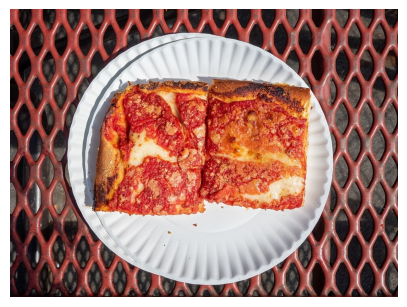

Q: What food is this and what toppings can you see?
A: The food in the image is a slice of pizza. The pizza slice is topped with tomato sauce and cheese. The pizza slice is placed on a white plate, which is sitting on a red dining table.


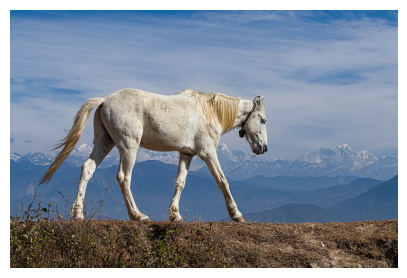

Q: Is this horse in a city or in nature? How can you tell?
A: The horse is in nature, as it is walking on a grassy hillside with mountains in the background. The presence of the natural landscape and the absence of any urban elements, such as buildings or roads, indicate that the horse is in a rural or natural setting.


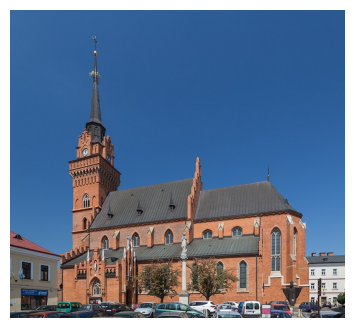

Q: What kind of building is this?
A: This is a large, old church with a tall clock tower.


'This is a large, old church with a tall clock tower.'

In [14]:
def assistant(image_path, question):
    image = Image.open(image_path).convert("RGB")
    plt.figure(figsize=(5, 4))
    plt.imshow(image)
    plt.axis("off")
    plt.show()
    answer = ask_llava(image, question)
    print("Q:", question)
    print("A:", answer)
    return answer


assistant("images/pizza2.jpg", "What food is this and what toppings can you see?")
assistant("images/horse1.jpg", "Is this horse in a city or in nature? How can you tell?")
assistant("images/building1.jpg", "What kind of building is this?")

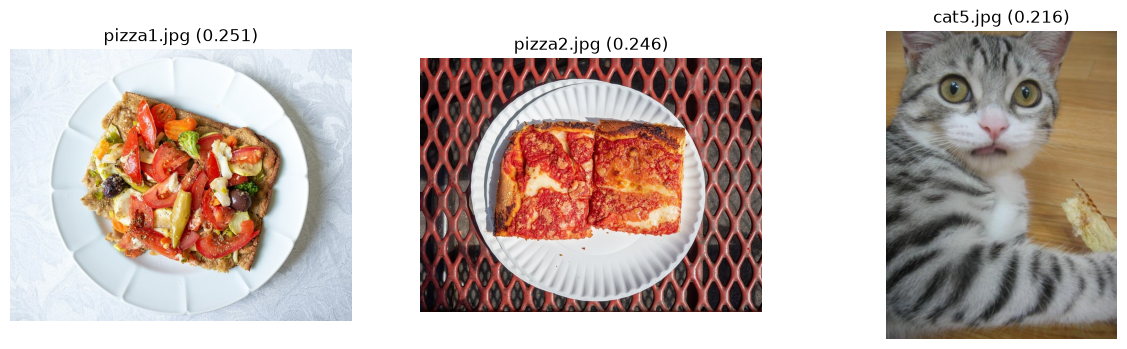

pizza1.jpg:


This image matches the search as it shows a plate with food on it.

pizza2.jpg:


This image matches the search as it shows a slice of pizza on a plate.

cat5.jpg:


The image matches the search query as the cat is laying on the floor with a piece of food, which is a banana.



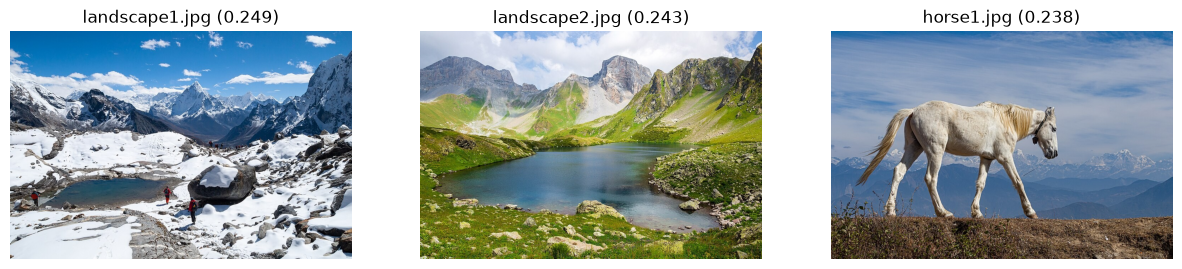

landscape1.jpg:


This image matches the search as it shows a snowy mountain with people standing on the snowy ground.

landscape2.jpg:


This image matches the search term as it features a lake surrounded by snowy mountains.

horse1.jpg:


The image matches the search query as it shows a white horse walking on a hill with snowy mountains in the background.



In [15]:
def search_and_explain(query, k=3):
    with torch.no_grad():
        text = processor(text=[query], return_tensors="pt", padding=True).to(device)
        q = as_tensor(model.get_text_features(**text))
    q = q / q.norm(dim=-1, keepdim=True)
    scores = (image_embeddings @ q.T).squeeze(1).cpu()
    top = scores.topk(k)

    fig, axes = plt.subplots(1, k, figsize=(5 * k, 4))
    for ax, score, i in zip(axes, top.values, top.indices):
        ax.imshow(db_images[i])
        ax.set_title(f"{os.path.basename(paths[i])} ({score.item():.3f})")
        ax.axis("off")
    plt.show()

    for i in top.indices:
        print(os.path.basename(paths[i]) + ":")
        print(ask_llava(db_images[i], f"Someone searched for '{query}'. Explain in one or two sentences why this image matches or doesn't match.", max_new_tokens=80))
        print()


search_and_explain("food on a plate")
search_and_explain("snowy mountains")

## Conclusion

CLIP is really good at matching images with text. It got all 10 cats and dogs right without any training, and searching the image folder with a sentence found the right pictures. The catch is that it can only choose between the options you give it, and the prompt wording changes the scores a bit.

LLaVA can actually talk about an image and answer questions, which CLIP can't do. It got 80% of the VQA questions right, but it struggles with counting and guessing locations. It also made up a bicycle that wasn't in the picture just because the question assumed there was one, so its answers need to be checked.

Putting them together works well: CLIP quickly finds the right images, and LLaVA explains what's in them.